# TP 4 — Autoencodeur et autoencodeur variationnel (VAE)
**Chapitre 1 · Fondements de l'IA générative** — durée indicative : 2 h

Objectifs :
1. Entraîner un autoencodeur et observer son espace latent.
2. Constater qu'un autoencodeur classique **génère mal** à partir d'un point latent quelconque.
3. Implémenter un VAE : encodeur probabiliste, astuce de reparamétrisation, perte ELBO.
4. Générer de nouvelles images et interpoler dans l'espace latent.

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
DATA_DIR = "./data"
tf = transforms.ToTensor()                     # pixels dans [0,1] (perte BCE)
train_set = datasets.FashionMNIST(DATA_DIR, train=True,  download=True, transform=tf)
test_set  = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=tf)
train_dl = DataLoader(train_set, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_set,  batch_size=512)
LATENT = 2       # 2 dimensions pour pouvoir visualiser l'espace latent
EPOCHS = 10

PyTorch 2.14.1 | device : mps


## 1. Autoencodeur

In [2]:
class Encoder(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.ReLU(),
                                 nn.Linear(512, 256), nn.ReLU(), nn.Linear(256, out_dim))
    def forward(self, x): return self.net(x)

class Decoder(nn.Module):
    def __init__(self, z_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(z_dim, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784))
    def forward(self, z): return self.net(z).view(-1, 1, 28, 28)   # logits

class AE(nn.Module):
    def __init__(self, z_dim=LATENT):
        super().__init__()
        self.enc, self.dec = Encoder(z_dim), Decoder(z_dim)
    def forward(self, x):
        z = self.enc(x)
        return self.dec(z), z

ae = AE().to(device)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
for ep in range(EPOCHS):
    ae.train(); tot = 0
    for x, _ in train_dl:
        x = x.to(device)
        logits, _ = ae(x)
        loss = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(x)
    print(f"ep {ep+1}  reconstruction = {tot/len(train_set):.1f}")

ep 1  reconstruction = 275.8
ep 2  reconstruction = 257.2
ep 3  reconstruction = 254.7
ep 4  reconstruction = 253.0
ep 5  reconstruction = 251.9
ep 6  reconstruction = 250.9
ep 7  reconstruction = 250.1
ep 8  reconstruction = 249.6
ep 9  reconstruction = 249.0
ep 10  reconstruction = 248.5


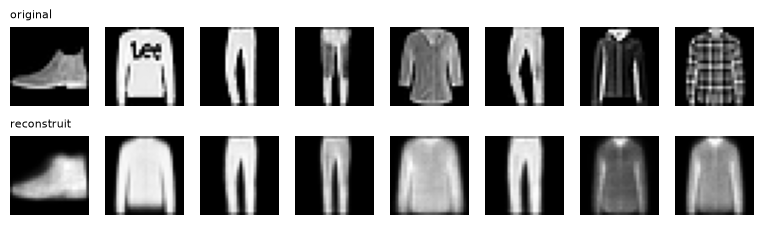

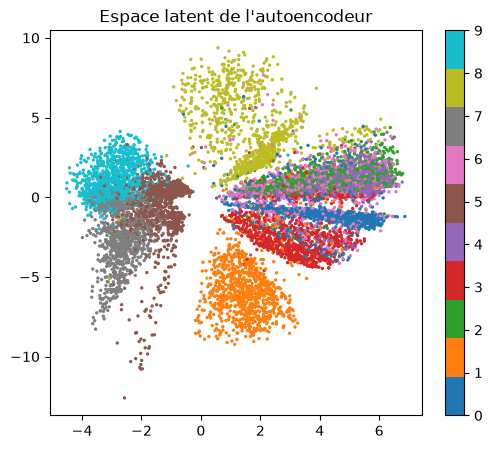

In [3]:
def show_recon(model, n=8):
    x, _ = next(iter(test_dl)); x = x[:n].to(device)
    model.eval()
    with torch.no_grad(): r = torch.sigmoid(model(x)[0])
    fig, ax = plt.subplots(2, n, figsize=(n*1.2, 2.6))
    for i in range(n):
        ax[0, i].imshow(x[i, 0].cpu(), cmap="gray"); ax[1, i].imshow(r[i, 0].cpu(), cmap="gray")
        ax[0, i].axis("off"); ax[1, i].axis("off")
    ax[0, 0].set_title("original", fontsize=8, loc="left"); ax[1, 0].set_title("reconstruit", fontsize=8, loc="left")
    plt.show()

def plot_latent(encode, title):
    zs, ys = [], []
    with torch.no_grad():
        for x, y in test_dl:
            zs.append(encode(x.to(device)).cpu()); ys.append(y)
    z, y = torch.cat(zs), torch.cat(ys)
    plt.figure(figsize=(6, 5)); plt.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=2)
    plt.colorbar(); plt.title(title); plt.show()
    return z

show_recon(ae)
z_ae = plot_latent(ae.enc, "Espace latent de l'autoencodeur")

**Question.** L'espace latent est-il centré ? Compact ? Que produira le décodeur si l'on tire un point $z \sim \mathcal{N}(0, I)$ ? Testez :

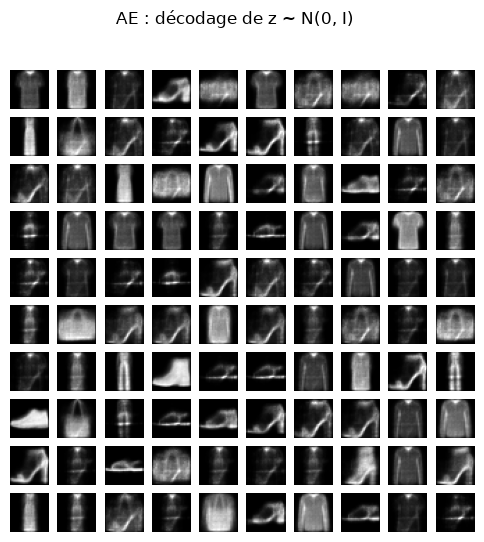

In [7]:
def sample_grid(decoder, title, n=10):
    with torch.no_grad():
        z = torch.randn(n*n, LATENT, device=device)
        imgs = torch.sigmoid(decoder(z)).cpu()
    fig, ax = plt.subplots(n, n, figsize=(6, 6))
    for i, a in enumerate(ax.flat): a.imshow(imgs[i, 0], cmap="gray"); a.axis("off")
    fig.suptitle(title); plt.show()

sample_grid(ae.dec, "AE : décodage de z ~ N(0, I)")

## 2. Autoencodeur variationnel
L'encodeur produit une **distribution** $q_\phi(z|x) = \mathcal{N}(\mu, \sigma^2)$. On maximise l'ELBO, soit on minimise :
$$\mathcal{L} = \underbrace{-\mathbb{E}_{q}[\log p_\theta(x|z)]}_{\text{reconstruction}} + \underbrace{D_{KL}\big(q_\phi(z|x)\,\|\,\mathcal{N}(0,I)\big)}_{\text{régularisation}}$$
avec, pour des gaussiennes : $D_{KL} = -\tfrac12\sum\big(1 + \log\sigma^2 - \mu^2 - \sigma^2\big)$.

**Astuce de reparamétrisation** : $z = \mu + \sigma \odot \varepsilon$, $\varepsilon\sim\mathcal{N}(0,I)$, pour que le gradient traverse l'échantillonnage.

In [4]:
class VAE(nn.Module):
    def __init__(self, z_dim=LATENT):
        super().__init__()
        self.enc = Encoder(2 * z_dim)          # sort [mu, logvar]
        self.dec = Decoder(z_dim)
        self.z_dim = z_dim
    def encode(self, x):
        h = self.enc(x)
        return h[:, :self.z_dim], h[:, self.z_dim:]    # mu, logvar
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparamétrisation
        return self.dec(z), mu, logvar

def vae_loss(logits, x, mu, logvar, beta=1.0):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
    kl = -0.5 * torch.sum(1 + logvar - mu**2 - logvar.exp()) / len(x)
    return rec + beta * kl, rec, kl

vae = VAE().to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
for ep in range(EPOCHS):
    vae.train(); s = torch.zeros(3)
    for x, _ in train_dl:
        x = x.to(device)
        logits, mu, logvar = vae(x)
        loss, rec, kl = vae_loss(logits, x, mu, logvar)
        opt.zero_grad(); loss.backward(); opt.step()
        s += torch.tensor([loss.item(), rec.item(), kl.item()]) * len(x)
    s /= len(train_set)
    print(f"ep {ep+1}  total={s[0]:.1f}  rec={s[1]:.1f}  KL={s[2]:.2f}")

ep 1  total=287.9  rec=281.5  KL=6.41
ep 2  total=267.3  rec=261.0  KL=6.24
ep 3  total=263.8  rec=257.5  KL=6.23
ep 4  total=261.9  rec=255.6  KL=6.28
ep 5  total=260.7  rec=254.4  KL=6.31
ep 6  total=259.9  rec=253.6  KL=6.34
ep 7  total=259.2  rec=252.8  KL=6.36
ep 8  total=258.6  rec=252.2  KL=6.39
ep 9  total=258.1  rec=251.7  KL=6.42
ep 10  total=257.5  rec=251.1  KL=6.46


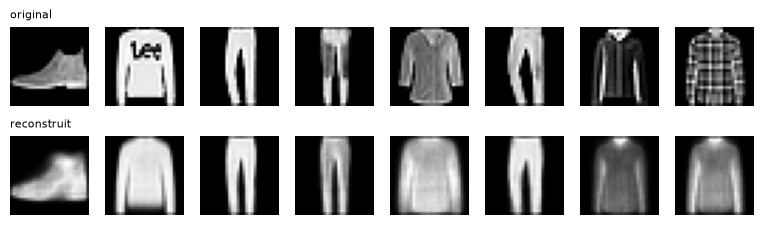

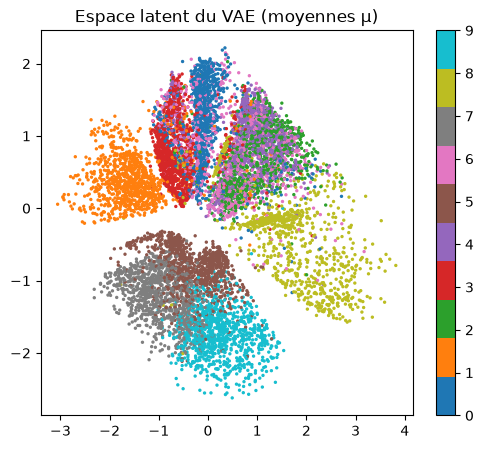

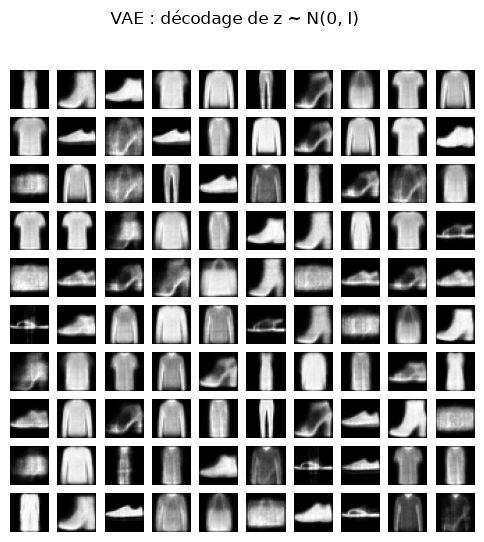

In [8]:
show_recon(vae)
z_vae = plot_latent(lambda x: vae.encode(x)[0], "Espace latent du VAE (moyennes μ)")
sample_grid(vae.dec, "VAE : décodage de z ~ N(0, I)")

## 3. Parcours de l'espace latent et interpolation

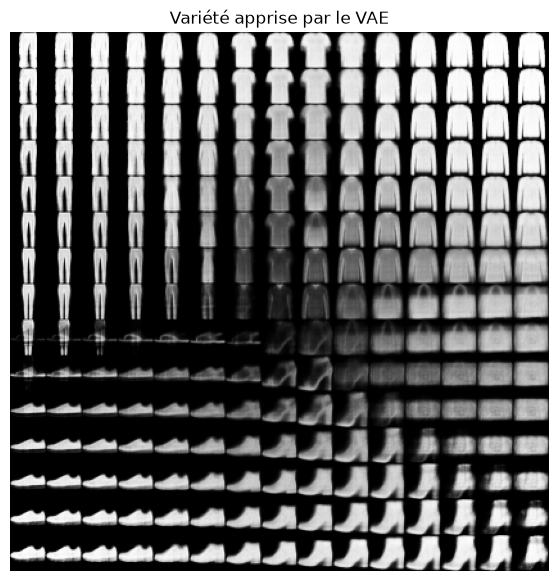

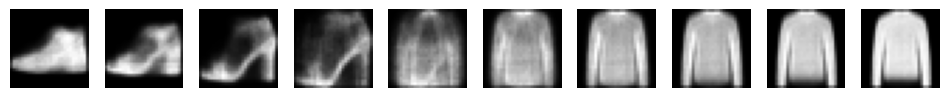

In [9]:
n = 15
g = torch.linspace(-2.5, 2.5, n)
zz = torch.stack(torch.meshgrid(g, g.flip(0), indexing="xy"), -1).reshape(-1, 2).to(device)
with torch.no_grad(): imgs = torch.sigmoid(vae.dec(zz)).cpu().view(n, n, 28, 28)
plt.figure(figsize=(7, 7))
plt.imshow(imgs.permute(0, 2, 1, 3).reshape(n*28, n*28), cmap="gray"); plt.axis("off")
plt.title("Variété apprise par le VAE"); plt.show()

# Interpolation entre deux images du jeu de test
x, _ = next(iter(test_dl))
with torch.no_grad():
    za, zb = vae.encode(x[0:1].to(device))[0], vae.encode(x[1:2].to(device))[0]
    path = torch.cat([(1 - a) * za + a * zb for a in torch.linspace(0, 1, 10)])
    imgs = torch.sigmoid(vae.dec(path)).cpu()
fig, ax = plt.subplots(1, 10, figsize=(12, 1.5))
for i, a in enumerate(ax): a.imshow(imgs[i, 0], cmap="gray"); a.axis("off")
plt.show()

## Exercices
1. **Comparaison.** Résumez en trois points la différence entre les espaces latents de l'AE et du VAE, et l'effet sur la génération.
2. **β-VAE.** Entraînez avec `beta=0.1` puis `beta=4`. Observez le compromis netteté des reconstructions / régularité de l'espace latent.
3. **Dimension latente.** Passez `LATENT` à 16. La reconstruction s'améliore-t-elle ? Comment visualiser l'espace latent désormais (indice : t-SNE ou PCA) ?
4. **VAE convolutif.** Remplacez `Encoder`/`Decoder` par des couches `Conv2d` / `ConvTranspose2d`.
5. **Ouverture.** Pourquoi les échantillons du VAE sont-ils flous ? Quelles familles de modèles (GAN, diffusion) cherchent à corriger ce défaut ? (Chapitre 6)

In [ ]:
# À compléter